In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
import seaborn as sns

In [ ]:
df = pd.read_csv("2-multiplegradesdataset.csv")

In [ ]:
df.head(5)

,Study Hours,Sleep Hours,Attendance Rate,Social Media Hours,Exam Score
0,4.7,7.3,82.9,3.3,80.7
1,3.8,6.6,87.9,3.3,76.0
2,5.0,6.3,88.3,2.3,89.1
3,6.3,7.6,86.0,3.2,95.9
4,3.6,8.0,89.2,3.3,70.5


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Study Hours         50 non-null     float64
 1   Sleep Hours         50 non-null     float64
 2   Attendance Rate     50 non-null     float64
 3   Social Media Hours  50 non-null     float64
 4   Exam Score          50 non-null     float64
dtypes: float64(5)
memory usage: 2.1 KB


In [ ]:
df.describe()

,Study Hours,Sleep Hours,Attendance Rate,Social Media Hours,Exam Score
count,50.00000,50.000000,50.000000,50.00000,50.00000
mean,3.66800,7.022000,89.736000,3.09000,76.07000
std,1.40123,0.874419,4.924813,0.89699,11.70915
min,1.10000,4.400000,80.400000,1.50000,56.90000
25%,2.67500,6.500000,85.625000,2.22500,68.07500
50%,3.60000,7.050000,90.100000,3.20000,73.55000
75%,4.50000,7.575000,92.550000,3.57500,84.17500
max,6.80000,8.600000,100.000000,5.70000,100.00000


In [ ]:
df.isnull().sum()

,0
Study Hours,0
Sleep Hours,0
Attendance Rate,0
Social Media Hours,0
Exam Score,0


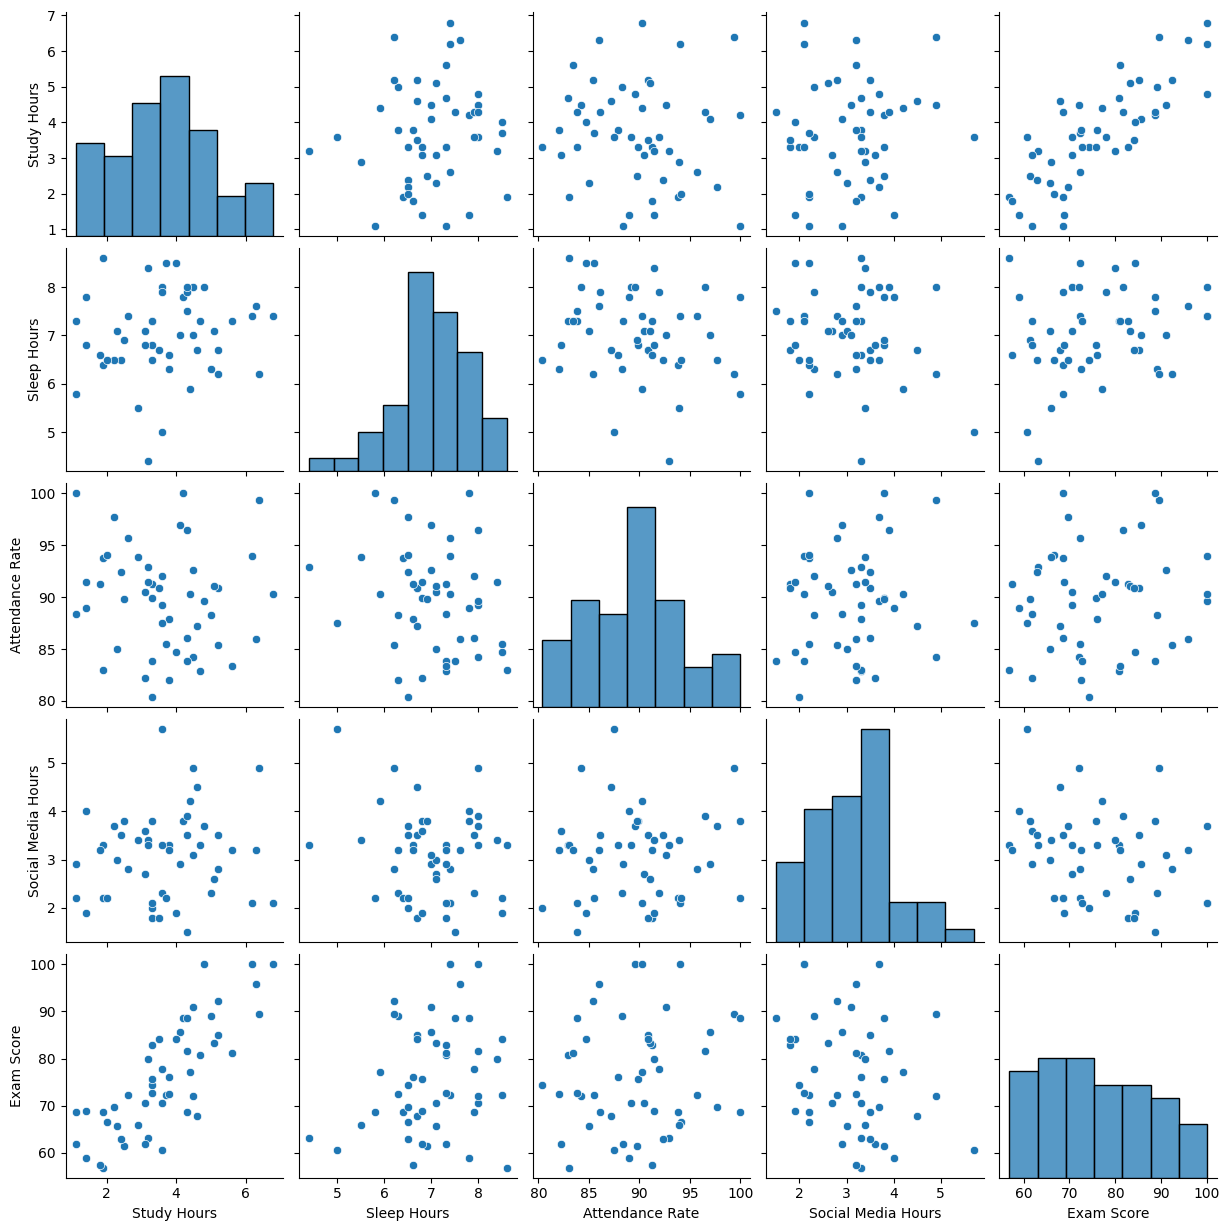

In [ ]:
sns.pairplot(df)
plt.show()

In [ ]:
df.corr()

,Study Hours,Sleep Hours,Attendance Rate,Social Media Hours,Exam Score
Study Hours,1.000000,0.114015,-0.112860,0.115023,0.804266
Sleep Hours,0.114015,1.000000,-0.222024,-0.177166,0.227694
Attendance Rate,-0.112860,-0.222024,1.000000,0.068272,0.123791
Social Media Hours,0.115023,-0.177166,0.068272,1.000000,-0.248743
Exam Score,0.804266,0.227694,0.123791,-0.248743,1.000000


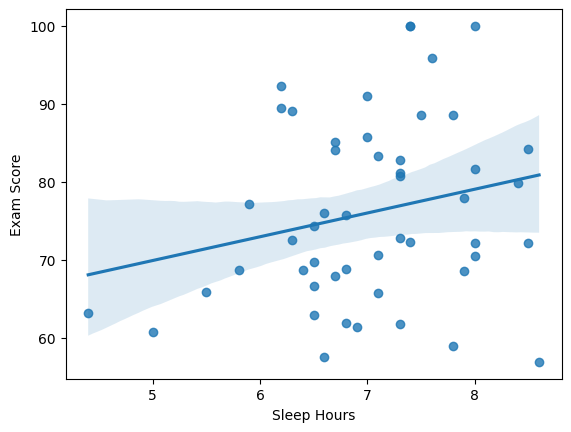

In [ ]:
#positive correlation
sns.regplot(x = df['Sleep Hours'], y = df['Exam Score'])
plt.show()

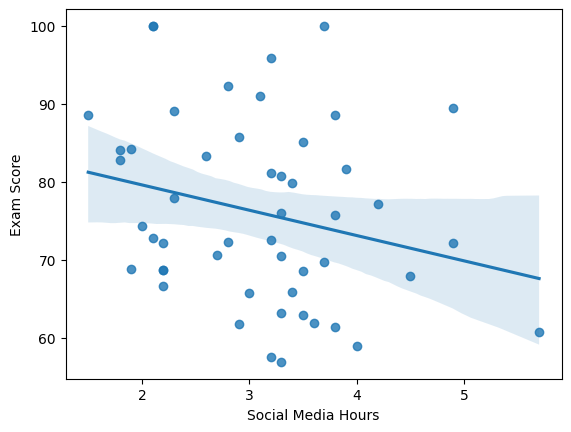

In [ ]:
#negative correlation
sns.regplot(x = df['Social Media Hours'], y = df['Exam Score'])
plt.show()

In [ ]:
#independent and dependent
X = df[["Study Hours", "Sleep Hours", "Attendance Rate", "Social Media Hours"]]
y = df["Exam Score"]

In [ ]:
#train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=15)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
new_student = [[5, 7, 90, 2]]

In [ ]:
new_student_scaler = sc.transform(new_student)
lr.predict(new_student_scaler)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([90.88471349])

In [ ]:
#prediction
y_pred = lr.predict(X_test)

In [ ]:
y_pred

array([ 67.04704385,  57.90545589,  83.63084813,  63.69399367,
        69.73079557,  80.76485587,  93.76445033,  65.93953528,
        64.58675718,  78.42296106,  56.67860558,  64.44046585,
       102.60438643])

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error

In [ ]:
mse = mean_squared_error(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

In [ ]:
print("mse: ", mse)
print("mae: ", mae)
print("rmse: ", rmse)
print("r2: ", r2)

mse:  14.600589378986257
mae:  3.277026485962786
rmse:  3.8210717578954543
r2:  0.915670734577271


In [ ]:
#adjusted R-squared
print("adj r2:", 1 - (1-r2)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1))

adj r2: 0.8735061018659065


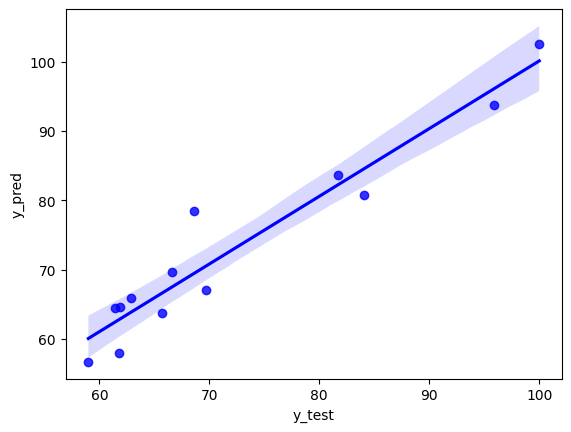

In [ ]:
sns.regplot(x = y_test, y = y_pred, color = 'b')
plt.xlabel('y_test')
plt.ylabel('y_pred')
plt.show()

In [ ]:
residuals = y_test - y_pred
residuals

,Exam Score
35,2.652956
37,3.894544
41,-1.930848
26,2.006006
38,-3.130796
43,3.335144
3,2.135550
33,-3.039535
30,-2.686757
36,-9.822961


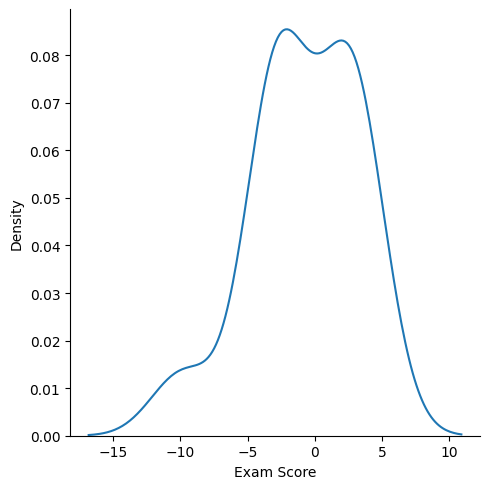

In [ ]:
sns.displot(residuals,kind='kde')
plt.show()

In [ ]:
lr.intercept_

np.float64(77.41081081081082)

In [ ]:
lr.coef_

array([ 9.28014703,  1.78967062,  3.24340001, -4.08127695])